# EVE con supuestos de comportamiento: depósitos a la vista, betas de depósitos y prepagos

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 02 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- dividir un depósito a la vista en una parte no estable y una parte estable con los topes del marco estandarizado, y decir qué cambia cuando se quitan los topes;
- explicar la cartera replicante de un depósito, leer sus pesos y su plazo promedio ponderado, y decir por qué esos pesos son inestables;
- aplicar un beta de depósitos con traspaso distinto al alza y a la baja, y las conversiones de prepago y de rescate anticipado (SMM, CPR, PSA y los multiplicadores por choque);
- calcular la medida de riesgo EVE con y sin la capa de comportamiento, leer la prueba de valores atípicos, y decir por qué el motor prueba ambas juntas;
- comparar cada recálculo con el valor versionado, nombrando la versión del motor que lo calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import behavioural, eve_nii, shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son el caso C14, el riesgo de tasa de interés en el libro de banca (IRRBB) del banco que quebró en marzo de 2023, en tres fechas de valoración, 2021-Q4, 2022-Q2 y 2022-Q4, tal como Contraste lo versiona. Los reportes de condición de la FDIC (FDIC BankFind financials, https://api.fdic.gov/banks/financials) y la curva a la par del Tesoro de EE. UU. (https://home.treasury.gov/resource-center/data-chart-center/interest-rates) son fuentes de dominio público de la clase de licencia `mirror-allowed`. El banco es **real en agregado y sintético en comportamiento**: el reporte no trae comportamiento de depósitos, así que la proporción y el plazo de los depósitos estables, el prepago y el rescate anticipado los declara Contraste y quedan rotulados como sintéticos; los betas de depósitos y los pesos de la cartera replicante se ajustan con el historial de reportes hasta cada fecha y nunca leen datos posteriores. El dinero está en miles de USD y un delta EVE positivo es una pérdida.

- **Archivos que se leen:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` y `vd-2022-q4.json` (`outputs.nmd_segments`, `behavioural_comparison`, `scenarios`; `tests`; `impact`) y `data/derived/C14/models-svb-2021-2022.json` (`fit.nmd_models`, `multipliers`).

La celda siguiente carga los cuatro archivos e imprime la versión del motor que los calculó.

In [2]:
# Cargar las tres fechas de valoración y el documento de modelos (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
docs = {q: json.loads((derived / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in ("2021-Q4", "2022-Q2", "2022-Q4")}
fit = json.loads((derived / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
out = docs["2022-Q2"]["outputs"]
MID = slotting.bucket_grid().midpoints
r0 = np.array(out["curve"]["zero_rates_at_midpoints"])
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
# Nombres en este idioma de los valores propios del documento (los identificadores del archivo quedan como están)
NAME = {"retail-transactional": "minorista transaccional", "retail-non-transactional": "minorista no transaccional",
        "wholesale": "mayorista", "behavioural": "conductual", "contractual": "contractual",
        "parallel-up": "paralelo al alza", "parallel-down": "paralelo a la baja", "steepener": "empinamiento",
        "flattener": "aplanamiento", "short-up": "corto al alza", "short-down": "corto a la baja",
        True: "sí", False: "no"}

for q, d in docs.items():
    print(q, d["outputs"]["valuation_date"], "| calculado por riskvalidation", d["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("segmentos de depósitos a la vista al 2022-Q2:", [s["category"] for s in out["nmd_segments"]])

2021-Q4 2021-12-31 | calculado por riskvalidation 0.8.1 | instalado 0.8.1
2022-Q2 2022-06-30 | calculado por riskvalidation 0.8.1 | instalado 0.8.1
2022-Q4 2022-12-31 | calculado por riskvalidation 0.8.1 | instalado 0.8.1
segmentos de depósitos a la vista al 2022-Q2: ['retail-transactional', 'retail-non-transactional', 'wholesale']


## Método

El método tiene cinco pasos: (1) la división de un depósito a la vista, (2) la cartera replicante, (3) el beta de depósitos, (4) prepago y rescate anticipado, (5) el EVE con y sin la capa de comportamiento.

### Paso 1: la división de un depósito a la vista con los topes del estándar

Un depósito a la vista (NMD) no tiene vencimiento contractual, pero una parte es estable. El marco estandarizado ubica la parte **no estable**, $(1 - s)\,B$ de un saldo $B$ con proporción estable $s$, en la banda a la vista, y la parte **estable**, $s\,B$, en las dos bandas cuyos puntos medios encierran el plazo promedio $m$ de esa parte, con pesos elegidos para que el plazo promedio ponderado sea exactamente $m$. La proporción y el plazo tienen tope por categoría (BCBS, SRP31.107 a SRP31.112, Tabla 4, https://www.bis.org/basel_framework/chapter/SRP/31.htm): minorista transaccional como máximo 90 por ciento y 5 años, minorista no transaccional 70 por ciento y 4,5 años, mayorista 50 por ciento y 4 años:

$$s_{usado} = \min(s_{pedido},\ s_{tope}), \qquad m_{usado} = \min(m_{pedido},\ m_{tope})$$

La función `nmd_split` del motor devuelve los flujos de 19 bandas, el pedido, el tope y el valor usado de ambos, y si algún tope actuó. El producto pide valores sobre todos los topes a propósito (pedidos sintéticos de 95, 75 y 60 por ciento), así que el tratamiento estandarizado los corta y lo dice. La celda siguiente divide los tres segmentos del balance de 2022-Q2, compara cada resultado con el segmento versionado y muestra los flujos.

In [3]:
# Dividir cada segmento con el motor, compararlo con el segmento versionado y mostrar los flujos en las bandas
splits = {}
for seg in out["nmd_segments"]:
    r = slotting.nmd_split(seg["balance"], seg["category"], seg["requested_core_share"], seg["requested_core_maturity_years"])
    splits[seg["category"]] = r
    same = (r.core_share_used, r.core_maturity_used_years, r.cap_applied) == (seg["core_share_used"], seg["core_maturity_used_years"], seg["cap_applied"])
    print(f"{NAME[seg['category']]}: saldo {seg['balance']:,.0f} | pedido {r.requested_core_share:.2f}/{r.requested_core_maturity_years:.1f} y | tope {r.core_share_cap:.2f}/{r.core_maturity_cap_years:.1f} y | usado {r.core_share_used:.2f}/{r.core_maturity_used_years:.1f} y")
    print(f"    tope aplicado: {NAME[r.cap_applied]} | igual al segmento versionado: {NAME[same]}")
    print("    flujos por banda (banda: monto):", {k + 1: round(float(v)) for k, v in enumerate(r.flows) if v})

minorista transaccional: saldo 2,723,410 | pedido 0.95/6.0 y | tope 0.90/5.0 y | usado 0.90/5.0 y
    tope aplicado: sí | igual al segmento versionado: sí
    flujos por banda (banda: monto): {1: 272341, 11: 1225535, 12: 1225535}
minorista no transaccional: saldo 1,726,590 | pedido 0.75/5.0 y | tope 0.70/4.5 y | usado 0.70/4.5 y
    tope aplicado: sí | igual al segmento versionado: sí
    flujos por banda (banda: monto): {1: 517977, 11: 1208613}
mayorista: saldo 185,381,000 | pedido 0.60/5.0 y | tope 0.50/4.0 y | usado 0.50/4.0 y
    tope aplicado: sí | igual al segmento versionado: sí
    flujos por banda (banda: monto): {1: 92690500, 10: 46345250, 11: 46345250}


La división tiene dos propiedades que verifica la celda siguiente: los flujos suman el saldo, y el plazo promedio ponderado de la parte estable es el plazo estable usado. También compara los flujos del motor con las partidas versionadas del balance: el segmento minorista transaccional es la partida L1 y el segmento mayorista es la suma de las partidas L2 y L4, cuyos flujos versionados son los negativos de los del motor, porque el documento guarda los pasivos con signo negativo.

In [4]:
# Verificar las dos propiedades de la división y comparar los flujos del motor con las partidas versionadas L1, L2 y L4
items = {it["item_id"]: it for it in out["balance_sheet"]["items"]}

def committed_flows(item_ids):
    vector = np.zeros(19)
    for item_id in item_ids:
        for row in items[item_id]["cash_flows"]["behavioural"]:
            vector[row["bucket"] - 1] += row["amount"]
    return -vector

for category, ids in (("retail-transactional", ["L1"]), ("wholesale", ["L2", "L4"])):
    r = splits[category]
    balance = next(s["balance"] for s in out["nmd_segments"] if s["category"] == category)
    core = r.flows.copy()
    core[0] -= (1.0 - r.core_share_used) * balance
    print(f"{NAME[category]}: los flujos suman el saldo {NAME[bool(np.isclose(r.flows.sum(), balance))]} | plazo promedio de la parte estable (a) {(core * MID).sum() / core.sum():.4f}"
          f" | igual a las partidas versionadas {NAME[bool(np.allclose(r.flows, committed_flows(ids)))]}")

minorista transaccional: los flujos suman el saldo sí | plazo promedio de la parte estable (a) 5.0000 | igual a las partidas versionadas sí
mayorista: los flujos suman el saldo sí | plazo promedio de la parte estable (a) 4.0000 | igual a las partidas versionadas sí


Lo que valen los topes. La celda siguiente toma el segmento mayorista, el más grande por lejos, y calcula el valor presente de sus flujos con los topes y con el pedido tal como se declaró (`enforce_caps=False`), usando la curva cero de la fecha. El pedido es más largo y más estable de lo que el estándar permite, así que los depósitos parecen más duraderos, su valor presente como pasivo es menor y el EVE del banco es mayor: los topes impiden que el supuesto haga ver al banco más seguro de lo que el estándar permite.

In [5]:
# Valor presente de los depósitos mayoristas con los topes y con el pedido tal como se declaró, sobre la curva cero de la fecha
seg = next(s for s in out["nmd_segments"] if s["category"] == "wholesale")
capped = slotting.nmd_split(seg["balance"], "wholesale", seg["requested_core_share"], seg["requested_core_maturity_years"])
asked = slotting.nmd_split(seg["balance"], "wholesale", seg["requested_core_share"], seg["requested_core_maturity_years"], enforce_caps=False)
pv_capped = eve_nii.eve(capped.flows, r0, MID)
pv_asked = eve_nii.eve(asked.flows, r0, MID)
print("tope aplicado: con topes", NAME[capped.cap_applied], "| sin topes", NAME[asked.cap_applied])
print(f"valor presente del pasivo con los topes {pv_capped:16,.0f}")
print(f"valor presente del pasivo como se pidió {pv_asked:16,.0f}")
print(f"EVE aumentado por no aplicar los topes {pv_capped - pv_asked:16,.0f}")

tope aplicado: con topes sí | sin topes no
valor presente del pasivo con los topes      174,964,140
valor presente del pasivo como se pidió      169,928,511
EVE aumentado por no aplicar los topes        5,035,629


### Paso 2: la cartera replicante

El estándar pone topes a los supuestos del depósito; el modelo propio de un banco tiene que elegirlos. El modelo interno más común es la **cartera replicante estática**: elegir pesos $w_j \ge 0$ que sumen uno sobre tramos rodantes de plazos $m_j$ de modo que el margen $\mu_t = \sum_j w_j\, y_{jt} - i_t$, el rendimiento replicante menos la tasa al cliente $i_t$, tenga la menor varianza posible. Un tramo rodante de plazo $m$ reinvertido en partes iguales durante su vida tiene un plazo promedio ponderado de $m/2$, así que el plazo implícito del depósito es

$$WAM = \frac{1}{2} \sum_j w_j\, m_j$$

(BCBS d368, nota 38, https://www.bis.org/bcbs/publ/d368.htm, según se lee en el dossier 05, D.3; la versión dinámica es Kalkbrener y Willing, 2004, https://doi.org/10.1016/S0378-4266(03)00131-6). La función `replicating_portfolio` del motor resuelve el problema con restricciones de forma exacta hasta 10 tramos, y `weighted_average_maturity` aplica la fórmula. Primero, los ajustes versionados: los pesos del modelo mayorista en cada fecha y el plazo promedio que el motor da para ellos.

In [6]:
# Los pesos versionados de la cartera replicante en cada fecha y el plazo promedio que el motor da para ellos
for model in fit["nmd_models"]:
    maturities = np.array([t["maturity_years"] for t in model["tranches"]])
    weights = np.array([t["weight"] for t in model["tranches"]])
    wam = behavioural.weighted_average_maturity(maturities, weights)
    used = {float(m): round(float(w), 4) for m, w in zip(maturities, weights) if w > 0}
    print(model["valuation_date"], NAME[model["category"]], "| tramos con peso (años: peso)", used)
    print(f"    plazo promedio (a) {wam:.4f} | versionado {model['weighted_average_maturity_years']:.4f} | volatilidad del margen {model['margin_volatility']:.5f}")

2021-12-31 mayorista | tramos con peso (años: peso) {0.25: 0.0493, 10.0: 0.9507}
    plazo promedio (a) 4.7595 | versionado 4.7595 | volatilidad del margen 0.00803
2022-06-30 mayorista | tramos con peso (años: peso) {0.25: 0.1631, 10.0: 0.8369}
    plazo promedio (a) 4.2049 | versionado 4.2049 | volatilidad del margen 0.00768
2022-12-31 mayorista | tramos con peso (años: peso) {10.0: 1.0}
    plazo promedio (a) 5.0000 | versionado 5.0000 | volatilidad del margen 0.00823


Los pesos saltan entre fechas: en 2021-Q4 casi todo está en el tramo de 10 años, en 2022-Q4 está entero allí. El historial versionado viene de los reportes del banco, que no se pueden volver a correr aquí; para ver cómo se comporta el optimizador, la celda siguiente construye un **ejemplo didáctico construido con verdad conocida**, con semilla: cinco tramos, curvas de rendimiento a partir de dos factores persistentes más ruido, y una tasa al cliente que es exactamente 40 por ciento del tramo de 1 año y 60 por ciento del tramo de 5 años, menos un margen, más ruido. No son datos del banco. El motor devuelve pesos cercanos a la verdad pero no iguales, porque los rendimientos de los tramos se mueven juntos, y un cambio pequeño en la muestra mueve los pesos entre tramos casi equivalentes: la inestabilidad que prueba el cuaderno 05.

In [7]:
# Un ejemplo construido con verdad conocida (con semilla): el motor recupera los pesos de forma aproximada
rng = np.random.default_rng(42)
quarters = 60
level, slope = np.zeros(quarters), np.zeros(quarters)
level[0], slope[0] = 0.03, 0.01
for t in range(1, quarters):
    level[t] = 0.03 + 0.9 * (level[t - 1] - 0.03) + rng.normal(0, 0.002)
    slope[t] = 0.01 + 0.8 * (slope[t - 1] - 0.01) + rng.normal(0, 0.002)
tranche_maturities = np.array([0.25, 1.0, 2.0, 5.0, 10.0])
tranche_yields = level[:, None] + slope[:, None] * (1 - np.exp(-tranche_maturities[None, :] / 2)) + rng.normal(0, 0.0003, (quarters, 5))
client_rate = 0.4 * tranche_yields[:, 1] + 0.6 * tranche_yields[:, 3] - 0.01 + rng.normal(0, 0.0002, quarters)
portfolio = behavioural.replicating_portfolio(client_rate, tranche_yields, tranche_maturities)
true_weights = np.array([0.0, 0.4, 0.0, 0.6, 0.0])
print("plazos de los tramos (a):", tranche_maturities)
print("pesos verdaderos:", true_weights)
print("pesos del motor:", np.round(portfolio.weights, 3), "| suma", round(float(portfolio.weights.sum()), 6))
print(f"plazo promedio: motor {behavioural.weighted_average_maturity(tranche_maturities, portfolio.weights):.4f} | verdadero {behavioural.weighted_average_maturity(tranche_maturities, true_weights):.4f} | volatilidad del margen {portfolio.margin_volatility:.5f}")

plazos de los tramos (a): [ 0.25  1.    2.    5.   10.  ]
pesos verdaderos: [0.  0.4 0.  0.6 0. ]
pesos del motor: [0.    0.371 0.042 0.56  0.027] | suma 1.0
plazo promedio: motor 1.7632 | verdadero 1.7000 | volatilidad del margen 0.00019


### Paso 3: el beta de depósitos

La tasa que un banco paga por un depósito no sigue a la tasa de mercado uno a uno. El **beta de depósitos** es el traspaso, y es asimétrico: un banco traspasa las alzas despacio y las bajas rápido. Con la tasa al cliente $i$, un cambio de mercado $\Delta r$ y los betas al alza y a la baja:

$$i_{nueva} = i + \beta\, \Delta r, \qquad \beta = \beta_{alza}\ \text{si}\ \Delta r \ge 0,\ \beta_{baja}\ \text{en otro caso}$$

(Drechsler, Savov y Schnabl, 2021, https://doi.org/10.1111/jofi.13013; dossier 05, D.3). Un beta bajo significa que los depósitos se comportan como pasivos de tasa fija y larga duración, y por eso importa. La función `deposit_beta_passthrough` del motor no aplica piso al resultado; el llamador lo aplica. El modelo versionado ajusta ambos betas en cada fecha por mínimos cuadrados a través del origen sobre los últimos 16 trimestres del costo de los depósitos contra el rendimiento del Tesoro a 3 meses. La celda siguiente imprime los betas ajustados en las tres fechas y los aplica a una tasa al cliente de 1 por ciento para un movimiento de mercado de +100 y de -100 pb.

In [8]:
# Los betas ajustados en las tres fechas y el traspaso de +100 y -100 pb sobre una tasa al cliente de 1 por ciento
for model in fit["nmd_models"]:
    b = model["deposit_beta"]
    up = behavioural.deposit_beta_passthrough(0.01, 0.01, b["up"], b["down"])
    down = behavioural.deposit_beta_passthrough(0.01, -0.01, b["up"], b["down"])
    print(f"{model['valuation_date']} beta al alza {b['up']:.4f} beta a la baja {b['down']:.4f} | tasa al cliente tras +100 pb {up:.5f} tras -100 pb {down:.5f}")
print("beta usado por el NII dinámico al 2022-Q2 (el valor al alza):", round(out["assumptions"]["deposit_beta"]["value"], 4))

2021-12-31 beta al alza 0.0236 beta a la baja 0.0315 | tasa al cliente tras +100 pb 0.01024 tras -100 pb 0.00969
2022-06-30 beta al alza 0.0748 beta a la baja 0.0315 | tasa al cliente tras +100 pb 0.01075 tras -100 pb 0.00969
2022-12-31 beta al alza 0.2611 beta a la baja 0.0315 | tasa al cliente tras +100 pb 0.01261 tras -100 pb 0.00969
beta usado por el NII dinámico al 2022-Q2 (el valor al alza): 0.0748


### Paso 4: prepago y rescate anticipado

Las hipotecas y los depósitos a plazo se pueden pagar antes, lo que acorta sus flujos. Dos convenciones miden la velocidad. La **mortalidad mensual simple** (SMM) es la fracción del saldo prepagada en un mes, y la **tasa de prepago condicional** (CPR) es la misma velocidad en tasa anual:

$$SMM = 1 - (1 - CPR)^{1/12}, \qquad CPR = 1 - (1 - SMM)^{12}$$

(Fuster, Lucca y Vickery, 2022, FRBNY Staff Report 1001, https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf; dossier 05, D.4). El **referente PSA** es una rampa estándar: con 100 por ciento PSA el CPR es 0,2 por ciento en el mes 1 y sube 0,2 por ciento al mes hasta 6 por ciento en el mes 30, plano después; $x$ por ciento PSA la escala, $CPR_m = \frac{x}{100}\min(0{,}002\, m,\ 0{,}06)$ (el texto primario de SIFMA no se obtuvo; el motor marca la fórmula como NO VERIFICADA contra él). El marco estandarizado escala las tasas base por choque con los multiplicadores de SRP31.119 (Tabla 5) y SRP31.125 (Tabla 6):

$$CPR_i = \min(1,\ \gamma_i\, CPR^0), \qquad TDRR_i = \min(1,\ u_i\, TDRR^0)$$

La celda siguiente convierte el supuesto de CPR de 8 por ciento del banco, imprime la rampa PSA en algunos meses para 100 y 150 por ciento, e imprime los multiplicadores y las tasas por choque, comparando los multiplicadores con la tabla versionada en el documento de modelos.

In [9]:
# Convertir CPR y SMM, imprimir la rampa PSA, y los multiplicadores y tasas por choque contra la tabla versionada
cpr0 = out["assumptions"]["prepayment_cpr"]["value"]
tdrr0 = out["assumptions"]["term_deposit_redemption_rate"]["value"]
smm = slotting.smm_from_cpr(cpr0)
print(f"CPR {cpr0:.4f} -> SMM {smm:.6f} -> CPR {slotting.cpr_from_smm(smm):.4f}")
months = np.array([1, 10, 30, 60])
print("meses:", months, "| PSA 100:", slotting.psa_cpr(months, 100.0), "| PSA 150:", slotting.psa_cpr(months, 150.0))
gamma = {row["shock"]: row["gamma"] for row in fit["multipliers"]["prepayment_gamma"]}
u = {row["shock"]: row["u"] for row in fit["multipliers"]["term_deposit_u"]}
print(f"{'':16s} {'γ':>5s} {'CPR':>7s} {'u':>5s} {'TDRR':>7s}  igual a la tabla versionada")
for s in shocks.SHOCKS:
    cpr_s, tdrr_s = slotting.prepayment_cpr(s, cpr0), slotting.term_deposit_redemption_rate(s, tdrr0)
    ok = bool(np.isclose(cpr_s, gamma[s] * cpr0) and np.isclose(tdrr_s, u[s] * tdrr0))
    print(f"{NAME[s]:22s} {gamma[s]:5.1f} {cpr_s:7.4f} {u[s]:5.1f} {tdrr_s:7.4f}  {NAME[ok]}")

CPR 0.0800 -> SMM 0.006924 -> CPR 0.0800
meses: [ 1 10 30 60] | PSA 100: [0.002 0.02  0.06  0.06 ] | PSA 150: [0.003 0.03  0.09  0.09 ]
                     γ     CPR     u    TDRR  igual a la tabla versionada
paralelo al alza         0.8  0.0640   1.2  0.0600  sí
paralelo a la baja       1.2  0.0960   0.8  0.0400  sí
empinamiento             0.8  0.0640   0.8  0.0400  sí
aplanamiento             1.2  0.0960   1.2  0.0600  sí
corto al alza            0.8  0.0640   1.2  0.0600  sí
corto a la baja          1.2  0.0960   0.8  0.0400  sí


Cuando el banco tiene historial por préstamo, el modelo de los profesionales es un **logit del SMM** sobre el incentivo de refinanciar (la tasa del contrato menos la tasa de mercado) y la antigüedad (la edad del préstamo en meses): $SMM = 1 / (1 + e^{-(b_0 + b_1\, incentivo + b_2\, antiguedad)})$ (dossier 05, D.4). La función `fit_prepayment_logit` del motor lo ajusta por máxima verosimilitud con el método de Newton y dice con claridad cuando no converge (sin excepción: el bake usa entonces el referente PSA). El reporte no trae historial por préstamo, así que el banco de este caso no ajusta uno; la celda siguiente ajusta un **ejemplo construido con verdad conocida**, con semilla, para mostrar la función, los errores estándar y la recuperación de los coeficientes.

In [10]:
# Ajustar el logit de prepago sobre un ejemplo construido con semilla y coeficientes conocidos, y leer la recuperación
rng = np.random.default_rng(42)
n_loans = 5000
incentive = rng.uniform(-0.01, 0.03, n_loans)
seasoning = rng.uniform(1, 60, n_loans)
true_coef = np.array([-5.0, 60.0, 0.03])
probability = 1.0 / (1.0 + np.exp(-(true_coef[0] + true_coef[1] * incentive + true_coef[2] * seasoning)))
prepaid = (rng.uniform(size=n_loans) < probability).astype(int)
logit = behavioural.fit_prepayment_logit(incentive, seasoning, prepaid)
print("préstamos:", logit.n, "| proporción prepagada:", round(float(prepaid.mean()), 4), "| convergió:", NAME[logit.converged])
for name, truth, estimate, error in zip(("b0", "b1", "b2"), true_coef, logit.coef, logit.std_err):
    print(f"{name}: verdadero {truth:8.3f} | estimación {estimate:8.3f} | error estándar {error:7.3f} | dentro de 2 errores estándar {NAME[bool(abs(estimate - truth) < 2 * error)]}")

préstamos: 5000 | proporción prepagada: 0.0358 | convergió: sí
b0: verdadero   -5.000 | estimación   -4.856 | error estándar   0.226 | dentro de 2 errores estándar sí
b1: verdadero   60.000 | estimación   56.801 | error estándar   7.385 | dentro de 2 errores estándar sí
b2: verdadero    0.030 | estimación    0.024 | error estándar   0.005 | dentro de 2 errores estándar sí


### Paso 5: el EVE con y sin la capa de comportamiento

Los seis choques del cuaderno 02 mueven el EVE. La **medida de riesgo EVE** es el peor de los seis: para cada choque, la suma de las monedas con pérdida, y luego el máximo entre choques (SRP31.129); con una sola moneda es el mayor delta EVE positivo, o cero si ninguno es positivo. La **prueba de valores atípicos supervisora** la compara con 15 por ciento del capital Tier 1 (SRP31.82 a SRP31.83; dossier 01, H.5) y se supera solo si la razón es estrictamente mayor. El pipeline calculó el delta EVE de cada choque dos veces, con los flujos conductuales con tope del Paso 1 y con todo depósito a la vista a un día (contractual), y versionó ambos. La celda siguiente toma los seis valores versionados de cada tratamiento bajo la calibración 2024, calcula la medida con `eve_risk_measure` (una matriz de seis choques por una moneda) y la prueba con `outlier_test`, y compara con los escenarios versionados.

In [11]:
# Los seis delta EVE de cada tratamiento, la medida de riesgo EVE y la prueba de valores atípicos, contra los escenarios versionados de 2022-Q2
rows = {s["shock"]: s for s in out["behavioural_comparison"] if s["calibration"] == "2024"}
tier1 = out["scenarios"][0]["outlier"]["tier1"]
print(f"{'':22s} {'conductual':>16s} {'contractual':>16s}")
for s in shocks.SHOCKS:
    print(f"{NAME[s]:22s} {rows[s]['delta_eve_behavioural']:16,.0f} {rows[s]['delta_eve_contractual']:16,.0f}")
measure, test = {}, {}
for treatment in ("behavioural", "contractual"):
    deltas = np.array([rows[s][f"delta_eve_{treatment}"] for s in shocks.SHOCKS]).reshape(6, 1)
    measure[treatment] = eve_nii.eve_risk_measure(deltas)
    test[treatment] = eve_nii.outlier_test(measure[treatment], tier1)
    block = next(b for b in out["scenarios"] if b["calibration"] == "2024" and b["nmd_assumption"] == treatment)
    print(f"{NAME[treatment]}: medida {measure[treatment]:14,.0f} | Tier 1 {tier1:,.0f} | razón {test[treatment].ratio:.4f} | umbral {test[treatment].threshold:.2f} | superado {NAME[test[treatment].breached]} | igual a la medida versionada {NAME[bool(np.isclose(measure[treatment], block['eve_risk_measure']))]} (peor choque: {NAME[block['worst_shock']]})")

                             conductual      contractual
paralelo al alza              3,389,351       12,611,380
paralelo a la baja           -4,783,706      -15,915,274
empinamiento                  3,418,185        8,589,837
aplanamiento                 -2,993,642       -5,921,844
corto al alza                    43,834        3,316,400
corto a la baja                  89,516       -3,343,657
conductual: medida      3,418,185 | Tier 1 16,349,000 | razón 0.2091 | umbral 0.15 | superado sí | igual a la medida versionada sí (peor choque: empinamiento)
contractual: medida     12,611,380 | Tier 1 16,349,000 | razón 0.7714 | umbral 0.15 | superado sí | igual a la medida versionada sí (peor choque: paralelo al alza)


El motor une las dos medidas en una sola prueba, `irrbb.eve_with_without_behavioural`, porque la revisión de SVB enseñó que el supuesto de comportamiento es la palanca que más mueve la medida (dossier 05, D.7). El estadístico de la prueba es la diferencia entre la medida contractual y la conductual como proporción del Tier 1, y su luz es verde si el estadístico absoluto es como máximo 0,05, ámbar como máximo 0,15 y roja por encima (umbrales internos de Contraste, no regulatorios); y es roja sea cual sea el tamaño cuando la medida conductual pasa la prueba de valores atípicos y la contractual la supera, lo que significa que los supuestos **esconden un exceso**. La celda siguiente la corre con las medidas de 2022-Q2 y compara con la fila versionada.

In [12]:
# Correr la prueba con y sin conducta sobre las medidas de 2022-Q2 y compararla con la fila versionada
result = rv_irrbb.eve_with_without_behavioural(measure["behavioural"], measure["contractual"], tier1)
print("test_id:", result.test_id, "| luz", result.light.value)
print(f"estadístico (diferencia sobre Tier 1) {result.statistic:.4f} | diferencia en dinero {result.metric:,.0f}")
print("razones conductual y contractual:", round(result.extras["thresholds"]["ratio_behavioural"], 4), round(result.extras["thresholds"]["ratio_contractual"], 4), "| exceso escondido:", NAME[result.extras["hidden_breach"]])
committed = next(t for t in docs["2022-Q2"]["tests"] if t["test_id"] == "irrbb.eve_with_without_behavioural")
print("fila versionada: luz, estadístico:", committed["light"], round(committed["statistic"], 4), "| igual:", NAME[bool(np.isclose(committed['statistic'], result.statistic) and committed['light'] == result.light.value)])

test_id: irrbb.eve_with_without_behavioural | luz red
estadístico (diferencia sobre Tier 1) 0.5623 | diferencia en dinero 9,193,196
razones conductual y contractual: 0.2091 0.7714 | exceso escondido: no
fila versionada: luz, estadístico: red 0.5623 | igual: sí


La misma comparación en las tres fechas de valoración, leída de los documentos versionados. Para cada fecha la celda imprime el Tier 1, las dos razones de la prueba de valores atípicos, el estadístico de la prueba con y sin conducta y su luz, y la versión del motor que calculó el documento.

In [13]:
# Las dos razones de valores atípicos y la prueba con y sin conducta en las tres fechas de valoración versionadas
print(f"{'':8s} {'Tier 1':>12s} {'razón conductual':>22s} {'razón contractual':>22s} {'estadístico':>12s}  luz   calculado por")
for q, d in docs.items():
    impact = d["impact"]
    row = next(t for t in d["tests"] if t["test_id"] == "irrbb.eve_with_without_behavioural")
    tier1_q = d["outputs"]["scenarios"][0]["outlier"]["tier1"]
    print(f"{q:8s} {tier1_q:12,.0f} {impact['outlier_ratio_behavioural']['value']:22.4f} {impact['outlier_ratio_contractual']['value']:22.4f} {row['statistic']:12.4f}  {row['light']:6s}  {d['provenance']['riskvalidation_version']}")

               Tier 1       razón conductual      razón contractual  estadístico  luz   calculado por
2021-Q4    14,622,000                 0.3406                 1.0629       0.7222  red     0.8.1
2022-Q2    16,349,000                 0.2091                 0.7714       0.5623  red     0.8.1
2022-Q4    16,995,000                 0.1808                 0.6463       0.4655  red     0.8.1


¿Cómo se vería un **exceso escondido**? Las tres fechas anteriores superan la prueba de valores atípicos bajo ambos tratamientos, así que la luz roja del motor viene del tamaño de la diferencia, no de un exceso escondido. La celda siguiente llama a la misma función del motor con **números construidos** (no los del banco) para mostrar el otro rojo: una medida conductual en 14 por ciento del Tier 1, bajo la línea de 15 por ciento, frente a una contractual en 40 por ciento. El supuesto de comportamiento hace que el banco pase una prueba que fallaría con la lectura contractual. Es el patrón que describe la revisión de la Reserva Federal en el banco quebrado, mostrado aquí como una llamada a la función, no como un hallazgo sobre ningún banco.

In [14]:
# Números construidos: la medida conductual pasa la línea de 15 por ciento y la contractual la supera
hidden = rv_irrbb.eve_with_without_behavioural(0.14 * 1000.0, 0.40 * 1000.0, 1000.0)
print("luz:", hidden.light.value, "| exceso escondido:", NAME[hidden.extras["hidden_breach"]], "| estadístico:", round(hidden.statistic, 4))
print("notes:", hidden.notes)

luz: red | exceso escondido: sí | estadístico: 0.26
notes: the behavioural assumptions hide an outlier breach


La última celda dibuja, a la izquierda, el delta EVE de cada choque con y sin la capa de comportamiento al 2022-Q2 y, a la derecha, la rampa PSA para 100 y 150 por ciento contra el supuesto plano de CPR de 8 por ciento del banco. A la izquierda las barras contractuales son mucho más altas que las conductuales bajo todo choque que pierde, y el peor choque cambia con el tratamiento. A la derecha la rampa llega a su techo en el mes 30, y el supuesto del banco queda entre los techos de las dos rampas.

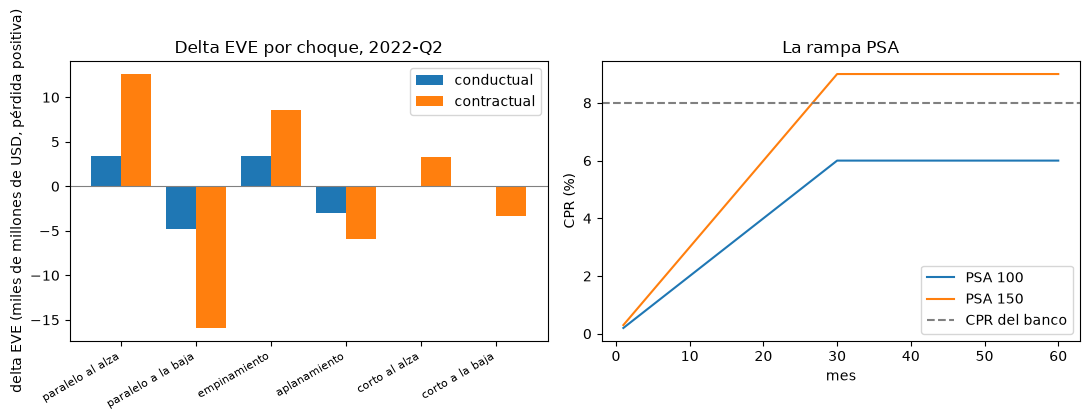

In [15]:
# Dibujar el delta EVE por choque con y sin la capa de comportamiento, y las rampas PSA contra el CPR del banco
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(6)
width = 0.4
left.bar(x - width / 2, [rows[s]["delta_eve_behavioural"] / 1e6 for s in shocks.SHOCKS], width, label="conductual")
left.bar(x + width / 2, [rows[s]["delta_eve_contractual"] / 1e6 for s in shocks.SHOCKS], width, label="contractual")
left.axhline(0, color="grey", linewidth=0.8)
left.set_xticks(x)
left.set_xticklabels([NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
left.set_ylabel("delta EVE (miles de millones de USD, pérdida positiva)")
left.set_title("Delta EVE por choque, 2022-Q2")
left.legend()
month = np.arange(1, 61)
right.plot(month, slotting.psa_cpr(month, 100.0) * 100, label="PSA 100")
right.plot(month, slotting.psa_cpr(month, 150.0) * 100, label="PSA 150")
right.axhline(cpr0 * 100, color="grey", linestyle="--", label="CPR del banco")
right.set_xlabel("mes")
right.set_ylabel("CPR (%)")
right.set_title("La rampa PSA")
right.legend()
fig.tight_layout()
plt.show()

## Resultados

- **Los topes.** Los tres pedidos superan sus topes, así que los tres se cortan: de 95 a 90 por ciento y de 6 a 5 años en los depósitos minoristas transaccionales, de 75 a 70 por ciento y de 5 a 4,5 años en los minoristas no transaccionales, de 60 a 50 por ciento y de 5 a 4 años en los mayoristas. En el segmento mayorista, 185.381.000 en total, la mitad va a un día y la otra mitad se reparte por igual entre las bandas de 3,5 y 4,5 años, cuyo promedio es 4 años. Los flujos suman el saldo y son iguales a las partidas versionadas. El pedido tal como se declaró bajaría el valor presente del pasivo mayorista en 5.035.629 y subiría el EVE en esa cantidad, cerca de un tercio del Tier 1 del banco de 16.349.000: los topes impiden que el supuesto haga ver al banco más seguro de lo que el estándar permite.
- **La cartera replicante.** Los ajustes mayoristas versionados ponen 95,1, 83,7 y 100 por ciento del peso en el tramo de 10 años en las tres fechas, y el plazo promedio del motor es 4,76, 4,20 y 5,00 años. Un promedio ponderado de tramos de hasta 10 años no puede superar 5 años, así que el último ajuste llegó al techo de su propio diseño, sobre los 4 años que el estándar permite a los depósitos mayoristas. En el ejemplo construido el motor encuentra 0,371 y 0,560 en los tramos de 1 y 5 años frente a una verdad de 0,4 y 0,6, con 0,042 y 0,027 en dos vecinos: los tramos se mueven juntos, así que carteras cercanas son casi igual de buenas, y el plazo promedio es 1,76 años frente a 1,70. Los pesos son una estimación con un objetivo plano, no una medición, y un validador debe preguntar cómo se mueven cuando se mueve la ventana (cuaderno 05).
- **El beta.** El beta al alza ajustado sube de 0,0236 a 0,0748 y a 0,2611 en las tres fechas, mientras el beta a la baja se queda en 0,0315, lo que es coherente con que los trimestres de alzas entren en las ventanas de estimación. Un banco con beta de 0,0236 traspasa 2,4 pb de un movimiento de +100 pb a sus depositantes, los depósitos parecen pasivos de tasa fija, y el EVE ante una alza se ve mejor de lo que es si el beta resulta después más alto.
- **Prepago.** El CPR de 8 por ciento es un SMM mensual de 0,6924 por ciento, y la ida y vuelta devuelve 0,08. Con 100 por ciento PSA el CPR llega a 6 por ciento en el mes 30, con 150 por ciento PSA a 9 por ciento, así que el supuesto del banco queda entre los dos techos. Los multiplicadores son iguales a la tabla versionada: los choques paralelo al alza, corto al alza y empinamiento bajan la tasa de prepago (6,4 por ciento) y los otros tres la suben (9,6 por ciento), mientras el rescate anticipado de depósitos a plazo es mayor para los choques paralelo al alza, corto al alza y aplanamiento (6 por ciento) y menor para los otros tres (4 por ciento). En el ejemplo construido el logit recupera los tres coeficientes dentro de dos errores estándar.
- **El EVE con y sin conducta.** Al 2022-Q2 la medida de riesgo es 3.418.185 con los flujos conductuales con tope (el empinamiento) y 12.611.380 con todo depósito a un día (el choque paralelo al alza), 3,7 veces más; como proporción del Tier 1 son 20,9 y 77,1 por ciento frente a una línea de 15 por ciento. Ambas superan la línea, así que la luz roja de la prueba con y sin conducta viene del tamaño de la diferencia (0,56 del Tier 1, muy sobre la compuerta de 0,15), no de un exceso escondido. La razón conductual baja de 34,1 a 20,9 y a 18,1 por ciento en las tres fechas, hacia la línea; la contractual de 106,3 a 77,1 y a 64,6 por ciento. La última llamada construida muestra el otro rojo: una medida conductual de 14 por ciento del Tier 1 pasa la prueba, una contractual de 40 por ciento la supera, y el motor lo marca.
- **Lo que el cuaderno no muestra.** La estabilidad de los pesos entre ventanas de estimación y la prueba que marca un cambio de comportamiento ante un exceso (cuaderno 05), el efecto dinámico del beta sobre el margen neto de intereses (cuaderno 04), y cualquier estimación de prepago sobre préstamos reales: el reporte no trae ninguna.

## Resumen

- Un depósito a la vista es una parte no estable a un día y una parte estable en las dos bandas que encierran su plazo estable; el estándar pone tope a la proporción y al plazo estables por categoría, y el motor informa el pedido, el tope y el valor usado.
- La cartera replicante elige pesos de tramos que minimizan la varianza del margen; los pesos no son estables porque los rendimientos de los tramos se mueven juntos, y el plazo implícito es la mitad del plazo ponderado de los tramos.
- El beta de depósitos es asimétrico y bajo, lo que hace que los depósitos se comporten como pasivos largos de tasa fija; el prepago y el rescate anticipado se convierten con SMM, CPR, PSA y los multiplicadores por choque.
- La medida de riesgo EVE es la peor de los seis choques; la capa de comportamiento la mueve en un múltiplo, y el motor prueba las dos lecturas juntas y marca un exceso que la lectura conductual esconde.
- Todo número versionado recalculado aquí es igual al versionado, calculado por la misma versión del motor; los dos ejemplos construidos tienen verdad conocida y no son datos del banco.

**Qué probar a continuación.** Cambia el pedido de proporción estable de `nmd_split` por debajo de su tope y mira la marca `cap_applied` y el EVE. Después sigue con el cuaderno 04, el NII dinámico y las distribuciones.

## Referencias

- BCBS, Standards: Interest rate risk in the banking book, SRP31.82 a SRP31.83 (la prueba de valores atípicos), SRP31.107 a SRP31.112 (depósitos a la vista, Tabla 4), SRP31.119 y SRP31.125 (Tablas 5 y 6) y SRP31.129 (la medida de riesgo EVE). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, nota 38 (la cartera replicante). https://www.bis.org/bcbs/publ/d368.htm
- Kalkbrener, M. y Willing, J. (2004), Risk management of non-maturing liabilities, Journal of Banking and Finance 28(7). https://doi.org/10.1016/S0378-4266(03)00131-6
- Drechsler, I., Savov, A. y Schnabl, P. (2021), Banking on deposits: maturity transformation without interest rate risk, Journal of Finance 76(3). https://doi.org/10.1111/jofi.13013
- Fuster, A., Lucca, D. y Vickery, J. (2022), Mortgage-backed securities, FRBNY Staff Report 1001. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf
- FDIC, BankFind financials, dominio público. https://api.fdic.gov/banks/financials
- Departamento del Tesoro de EE. UU., Daily Treasury Par Yield Curve Rates, dominio público. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 de la investigación de Contraste, secciones D.3, D.4 y D.7; dossier 01, sección H.5.